# P1-06. 마무리: 허깅페이스 업로드 + Gradio 데모 + GitHub README

노트북 1~5에서 **모델을 만들고 검증**했어요. 이번엔 그 결과를 **남에게 보여줄 수 있는 형태**로 정리해요.

| 섹션 | 할 일 | 🎯 왜 하나요? |
|---|---|---|
| 1~2 | E2 모델을 **허깅페이스 형식으로 저장** + 데모 코드(`app.py`) 작성 | 다른 사람이 `timm.create_model("hf-hub:내아이디/모델")` 한 줄로 쓸 수 있는 형태 |
| 3 | **데모 코드로 test 882장을 다시 평가** | 데모의 전처리가 학습 때와 *정말 똑같은지* 확인. 다르면 데모가 엉뚱한 답을 냄 (실무에서 자주 생기는 버그) |
| 4 | **모델 카드(README.md)** 작성 | 성능만이 아니라 **한계(노트북 5 결과)**까지 적는 연습. 의료 AI에서 가장 중요한 문서 |
| 5 | **허깅페이스 Hub에 업로드** | 처음에 얘기한 "허깅페이스 사용 경험" — 받아쓰기만이 아니라 **올려보기**까지 |
| 6 | **Gradio 데모** 실행 | 사진을 올리면 예측 + Grad-CAM이 나오는 웹페이지. 포트폴리오·면접용 |
| 7 | (선택) **허깅페이스 Spaces**에 데모 공개 | 링크 하나로 누구나 써볼 수 있게 |
| 8 | **GitHub README** + 그림 생성 | 저장소에 들어온 사람이 README만 보고 프로젝트 1 전체를 이해하게 |

**모델 선택: E2 (ResNet50 + 자르기 + 증강)**  
정확도는 E4(0.995)가 1등이지만 E2(0.988)와의 차이는 통계적으로 확실하지 않았고(노트북 5),  
E2는 **Grad-CAM이 뇌 안쪽에 가장 잘 집중**해서(안쪽 비율 0.883) Grad-CAM을 보여주는 데모에 가장 설득력 있어요.

**시작 전 준비**
1. 터미널(`.venv` 켠 상태)에서: `pip install gradio huggingface_hub`
2. 허깅페이스 계정 → 오른쪽 위 프로필 → **Settings → Access Tokens → Create new token** → 종류 **Write** 선택 → 토큰 복사해두기 (5번 섹션에서 붙여넣어요)

## 0. 준비

In [14]:
import os, sys, json, shutil, getpass, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm
import torch, timm
from timm.models._hub import save_for_hf
from sklearn.metrics import f1_score, confusion_matrix

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

DATA_ROOT = Path("../../data/raw").resolve()
OUT  = Path("../../outputs/p1").resolve()
PROJ = Path("..").resolve()                      # 01_classification_brain_mri 폴더
DEMO_DIR, FIG_DIR = PROJ / "demo", PROJ / "figures"
DEMO_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
HF_DIR = OUT / "hf_model_E2"                     # outputs는 .gitignore라 GitHub엔 안 올라감

MODEL_TAG = "E2"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# ▼▼ 본인 허깅페이스 아이디로 바꾸세요 ▼▼
HF_USERNAME = "yerim0827"
REPO_ID  = f"{HF_USERNAME}/brain-mri-tumor-resnet50-gradcam"
SPACE_ID = f"{HF_USERNAME}/brain-mri-tumor-demo"
print("프로젝트 폴더:", PROJ)

프로젝트 폴더: D:\yerimlee\medimg-study\01_classification_brain_mri


## 1. 모델을 허깅페이스 형식으로 저장

> 🎯 **왜 하나요?** 지금 `p1_04_E2.pt`에는 **가중치 숫자만** 들어 있어요. 불러오려면 "이건 ResNet50이고 클래스가 4개"라는 걸 코드로 따로 알려줘야 하죠.  
> 허깅페이스 형식으로 저장하면 **`config.json`(구조·클래스 이름) + `model.safetensors`(가중치)**가 같이 저장돼서, 받는 사람이 설정 없이 바로 쓸 수 있어요.  
> `safetensors`는 가중치 저장 형식인데, 일반 `.pt`와 달리 **열 때 임의 코드가 실행될 위험이 없어서** 허깅페이스 표준이에요.

In [2]:
model = timm.create_model("resnet50.a1_in1k", pretrained=False, num_classes=len(CLASSES))
model.load_state_dict(torch.load(OUT / f"p1_04_{MODEL_TAG}.pt", map_location="cpu"))
model.eval()

if HF_DIR.exists(): shutil.rmtree(HF_DIR)
save_for_hf(model, str(HF_DIR), model_config={"label_names": CLASSES}, safe_serialization=True)
print("저장된 파일:", [p.name for p in HF_DIR.iterdir()])
print(json.dumps(json.load(open(HF_DIR / "config.json")), indent=1, ensure_ascii=False)[:500], "...")

저장된 파일: ['config.json', 'model.safetensors']
{
 "architecture": "resnet50",
 "num_classes": 4,
 "num_features": 2048,
 "global_pool": "avg",
 "label_names": [
  "glioma",
  "meningioma",
  "notumor",
  "pituitary"
 ],
 "model_args": {
  "num_classes": 4,
  "in_chans": 3,
  "global_pool": "avg"
 },
 "pretrained_cfg": {
  "tag": "a1_in1k",
  "custom_load": false,
  "input_size": [
   3,
   224,
   224
  ],
  "test_input_size": [
   3,
   288,
   288
  ],
  "fixed_input_size": false,
  "interpolation": "bicubic",
  "crop_pct": 0.95,
  "test_c ...


## 2. 데모 코드(`app.py`) 작성

> 🎯 **왜 노트북이 아니라 별도 파일?** 웹 데모는 노트북 없이 `python app.py`로 실행되고, 허깅페이스 Spaces에 올릴 때도 이 파일 하나만 올리면 돼요.  
> 안에는 **학습 때와 똑같은 전처리**(머리 영역 자르기 → 256 → 224 → 3채널 → ImageNet 정규화), 예측, Grad-CAM이 들어 있어요.  
> 모델은 `MODEL_SOURCE`에서 불러와요: 지금은 방금 저장한 **로컬 폴더**, 업로드 후엔 **허깅페이스 Hub**.

In [3]:
APP_CODE = '"""뇌종양 MRI 4클래스 분류 데모 (교육·연구용, 진단용 아님)\n모델: ResNet50 (ImageNet 사전학습 → 뇌 영역 자르기 + 증강으로 fine-tuning)\n"""\nimport os\nimport numpy as np\nimport torch\nimport timm\nimport gradio as gr\nfrom PIL import Image\nfrom scipy import ndimage\nfrom torchvision.transforms import v2\nfrom pytorch_grad_cam import GradCAM\nfrom pytorch_grad_cam.utils.image import show_cam_on_image\n\nMODEL_SOURCE = os.environ.get("MODEL_SOURCE", "__MODEL_SOURCE__")   # "hf-hub:아이디/저장소" 또는 "local-dir:폴더경로"\nCLASSES = ["glioma", "meningioma", "notumor", "pituitary"]\nKOR = {"glioma": "신경교종 (glioma)", "meningioma": "수막종 (meningioma)",\n       "notumor": "종양 없음 (notumor)", "pituitary": "뇌하수체 종양 (pituitary)"}\n\nmodel = timm.create_model(MODEL_SOURCE, pretrained=True).eval()\ncam = GradCAM(model=model, target_layers=[model.layer4[-1]])\nMEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)\nSTD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)\nresize224 = v2.Resize((224, 224), antialias=True)\n\n\ndef head_mask(a, thr=20):\n    m = ndimage.binary_opening(a > thr, iterations=2)\n    lab, n = ndimage.label(m)\n    if n == 0:\n        return np.ones_like(a, bool)\n    sizes = ndimage.sum(m, lab, range(1, n + 1))\n    return ndimage.binary_fill_holes(lab == (np.argmax(sizes) + 1))\n\n\ndef brain_crop(a, thr=20, margin=0.04):\n    """학습 때와 똑같은 전처리: 머리 영역만 정사각형으로 자르기"""\n    ys, xs = np.where(head_mask(a, thr))\n    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()\n    side = max(y1 - y0, x1 - x0) * (1 + 2 * margin)\n    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2\n    y0, y1 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, a.shape[0]))\n    x0, x1 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, a.shape[1]))\n    return a[y0:y1, x0:x1]\n\n\ndef preprocess(img):\n    a = np.asarray(Image.fromarray(img).convert("L"))\n    a = np.array(Image.fromarray(brain_crop(a)).resize((256, 256), Image.BILINEAR))   # 복사본(쓰기 가능)\n    t = resize224(torch.from_numpy(a).unsqueeze(0)).float().div(255)      # 1×224×224, 0~1\n    x = (t.repeat(3, 1, 1) - MEAN) / STD\n    return x.unsqueeze(0), t[0].numpy()\n\n\ndef predict(img):\n    if img is None:\n        return None, None\n    x, gray = preprocess(img)\n    with torch.no_grad():\n        p = torch.softmax(model(x), 1)[0].numpy()\n    heat = cam(input_tensor=x, targets=None)[0]\n    overlay = show_cam_on_image(np.stack([gray] * 3, -1), heat, use_rgb=True)\n    return {KOR[c]: float(p[i]) for i, c in enumerate(CLASSES)}, overlay\n\n\nDESC = """**교육·연구용 데모입니다. 의료 진단에 사용하지 마세요.**\n\n뇌 MRI 사진 한 장을 올리면 4가지(신경교종 / 수막종 / 뇌하수체 종양 / 종양 없음) 중 무엇인지 예측하고,\n**Grad-CAM**으로 모델이 판단할 때 중요하게 본 영역(빨간색)을 보여줍니다.\n\n⚠️ **알려진 한계**: 학습 데이터(공개 Kaggle 파생 데이터)에는 클래스별 촬영 방식·단면 방향 차이가 있어,\n병변이 거의 안 보이는 16×16 해상도의 단순 모델로도 80%를 맞힐 수 있습니다.\n따라서 높은 정확도가 "종양을 잘 본다"는 뜻은 아닙니다. 외부 병원 데이터 검증, 환자 단위 분할은 하지 않았습니다.\n"""\n\ndemo = gr.Interface(\n    fn=predict,\n    inputs=gr.Image(type="numpy", label="뇌 MRI 사진 (단면 1장)"),\n    outputs=[gr.Label(num_top_classes=4, label="예측 확률"),\n             gr.Image(label="Grad-CAM (전처리로 머리 영역만 잘라낸 이미지 위에 표시)")],\n    title="뇌종양 MRI 분류 + Grad-CAM (학습용 데모)",\n    description=DESC,\n    examples=[[os.path.join(os.path.dirname(os.path.abspath(__file__)), "examples", f)]\n              for f in sorted(os.listdir(os.path.join(os.path.dirname(os.path.abspath(__file__)), "examples")))]\n             if os.path.isdir(os.path.join(os.path.dirname(os.path.abspath(__file__)), "examples")) else None,\n    flagging_mode="never",\n)\n\nif __name__ == "__main__":\n    demo.launch()\n'

(DEMO_DIR / "app.py").write_text(APP_CODE.replace("__MODEL_SOURCE__", f"local-dir:{HF_DIR.as_posix()}"), encoding="utf-8")
(DEMO_DIR / "requirements.txt").write_text("torch\ntorchvision\ntimm\ngrad-cam\nscipy\npillow\nnumpy\n", encoding="utf-8")
print("작성 완료:", DEMO_DIR / "app.py")
print("→ VS Code 탐색기에서 demo/app.py를 열어 코드를 한번 읽어보세요. 노트북 4·5에서 쓴 함수들이 그대로 들어 있어요.")

작성 완료: D:\yerimlee\medimg-study\01_classification_brain_mri\demo\app.py
→ VS Code 탐색기에서 demo/app.py를 열어 코드를 한번 읽어보세요. 노트북 4·5에서 쓴 함수들이 그대로 들어 있어요.


## 3. 데모 코드로 test 882장 다시 평가 (전처리 일치 확인) ⭐

> 🎯 **왜 하나요?**  
> 학습 코드와 데모 코드는 **따로 작성**됐어요. 리사이즈 순서·정규화 값 하나만 달라도 모델은 엉뚱한 답을 내는데, 에러는 안 나서 **조용히 틀려요.**  
> 그래서 데모의 `predict` 함수로 test를 다시 돌려서 **노트북 4·5의 E2 결과(acc 0.988, 오답 11장)와 똑같이 나오는지** 확인해요.  
> 실무에서 "학습 땐 잘 됐는데 배포하니 성능이 떨어졌다"의 흔한 원인이 이 **전처리 불일치(training-serving skew)**예요.

In [5]:
os.environ["MODEL_SOURCE"] = f"local-dir:{HF_DIR.as_posix()}"
sys.path.insert(0, str(DEMO_DIR))
import app; importlib.reload(app)

clean = pd.read_csv(OUT / "brain_index_clean.csv")
test_df = clean[clean["split"] == "test"].reset_index(drop=True)
y_test = test_df["label"].map({c: i for i, c in enumerate(CLASSES)}).values

probs = []
for p in tqdm(test_df["path"], desc="데모 코드로 test 예측"):
    img = np.asarray(Image.open(DATA_ROOT / p).convert("RGB"))
    x, _ = app.preprocess(img)
    with torch.no_grad():
        probs.append(torch.softmax(app.model(x), 1)[0].numpy())
probs = np.stack(probs); pred = probs.argmax(1)
cm = confusion_matrix(y_test, pred, labels=range(4))
METRICS = {"acc": float((pred == y_test).mean()), "macro_f1": float(f1_score(y_test, pred, average="macro")),
           "n_wrong": int((pred != y_test).sum()), "n_test": len(y_test),
           **{f"recall_{c}": float(cm[i, i] / cm[i].sum()) for i, c in enumerate(CLASSES)}}
print(json.dumps(METRICS, indent=1))
print("\n✅ 노트북 4·5의 E2(acc 0.988, 오답 11장)와 같으면 데모 전처리가 학습과 일치하는 거예요.")

데모 코드로 test 예측: 100%|██████████| 882/882 [01:50<00:00,  7.95it/s]


{
 "acc": 0.9875283446712018,
 "macro_f1": 0.9884621346270601,
 "n_wrong": 11,
 "n_test": 882,
 "recall_glioma": 0.976271186440678,
 "recall_meningioma": 1.0,
 "recall_notumor": 1.0,
 "recall_pituitary": 0.9863945578231292
}

✅ 노트북 4·5의 E2(acc 0.988, 오답 11장)와 같으면 데모 전처리가 학습과 일치하는 거예요.


## 4. 모델 카드 (README.md) 작성

> 🎯 **왜 하나요?** 허깅페이스 모델 페이지에 그대로 보이는 **설명서**예요. 의료 AI 모델 카드에는 성능보다 **"어디까지 믿을 수 있나"**가 더 중요해요.  
> 노트북 5에서 찾은 한계(지름길, 환자 단위 분할 없음, 외부 검증 없음, 사진 위 화살표)를 **숨기지 않고** 적는 게 핵심이에요.  
> 맨 위 `---` 사이 부분(YAML)은 허깅페이스가 검색·분류에 쓰는 정보예요.

In [6]:
M = METRICS
CARD = f"""---
license: cc-by-4.0
library_name: timm
pipeline_tag: image-classification
tags:
- medical-imaging
- brain-mri
- brain-tumor
- grad-cam
- educational
---

# Brain MRI 4-class classifier (ResNet50, 학습용)

> ⚠️ **교육·연구용 모델입니다. 의료 진단에 사용하지 마세요.**

뇌 MRI 단면 한 장을 **glioma / meningioma / notumor / pituitary** 4가지로 분류하는 모델입니다.
의료영상 딥러닝 독학 프로젝트의 결과물로, 성능보다 **"이 성능을 얼마나 믿을 수 있는가"를 검증한 과정**에 초점을 두었습니다.

## 모델
- 구조: ResNet50 (`timm` `resnet50.a1_in1k`, ImageNet 사전학습) → 4클래스로 fine-tuning
- 입력: 흑백 MRI → **머리 영역 기준 자르기** → 224×224, 3채널 복사, ImageNet 정규화
- 학습: AdamW (lr 1e-4, wd 1e-4) + cosine, 증강(85~100% 자르기, 좌우 반전, ±10° 회전, 밝기·대비 ±20%), val macro F1 기준 best, 혼합 정밀도

## 데이터
- Mendeley Data "Medical Imaging (CT scan, MRI, X-ray, and Microscopic Imagery) Data" 중 Brain Tumor 부분 (CC BY 4.0, 원 출처는 Kaggle 공개 데이터)
- **중복·누수 정리**: 픽셀 기반 유사 중복 검사(16×16 해시 + 64×64 픽셀 비교)로 7,023장 → 5,980장
  - 원본 test의 **31.5%(413장)가 train에 쌍둥이가 있어** 제거
- 분할: train 4,333 / val 765 / test 882 (원본 Training·Testing 폴더 기준, train에서 15%를 val로)

## 성능 (중복 정리된 test {M['n_test']}장)
| 지표 | 값 |
|---|---|
| Accuracy | {M['acc']:.3f} (95% bootstrap CI 0.980 ~ 0.994) |
| Macro F1 | {M['macro_f1']:.3f} |
| 오답 | {M['n_wrong']}장 |
| Recall (glioma / meningioma / notumor / pituitary) | {M['recall_glioma']:.3f} / {M['recall_meningioma']:.3f} / {M['recall_notumor']:.3f} / {M['recall_pituitary']:.3f} |
| ECE (보정 오차) | 0.0075 |
| Grad-CAM이 뇌 안쪽에 있는 비율 | 0.883 (안쪽 면적 비율 0.404) |

## ⚠️ 한계 — 꼭 읽어주세요
1. **데이터에 지름길(shortcut)이 있습니다.** 종양이 거의 안 보이는 **16×16 해상도의 로지스틱 회귀로도 80.7%**를 맞힙니다.
   특히 notumor(0.92)와 pituitary(0.88)는 촬영 방식·단면 방향 차이로 구분될 수 있습니다. 높은 정확도가 "종양을 잘 본다"는 뜻은 아닙니다.
2. **환자 단위 분할을 하지 못했습니다.** 데이터에 환자 ID가 없어, 같은 환자의 다른 단면이 train·test에 나뉘어 있을 수 있습니다.
   실제로 오답이 연속된 파일 번호(같은 환자·촬영 묶음 추정)에 몰려 있었습니다.
3. **외부 병원 데이터로 검증하지 않았습니다.** 다른 장비·병원의 사진에서는 성능과 확률 보정이 크게 달라질 수 있습니다.
4. 일부 사진에는 **종양을 가리키는 화살표 등 표시**가 있습니다.
5. 실제 진료는 여러 단면을 함께 보고 판단합니다. **단면 한 장 4분류는 현실을 크게 단순화한 문제**입니다.
6. 모델 간 비교(EfficientNet-B0 0.995 등)는 단일 시드 결과로, 시드 반복 없이 우열을 단정할 수 없습니다.

## 사용법
```python
import timm, torch
model = timm.create_model("hf-hub:{REPO_ID}", pretrained=True).eval()
print(model.pretrained_cfg["label_names"])   # ['glioma', 'meningioma', 'notumor', 'pituitary']
```
전처리(머리 영역 자르기 등)는 데모 코드(`app.py`)의 `preprocess` 함수를 참고하세요. 학습과 다른 전처리를 쓰면 성능이 크게 떨어집니다.
"""
(HF_DIR / "README.md").write_text(CARD, encoding="utf-8")
print(CARD[:1500], "\n...")

---
license: cc-by-4.0
library_name: timm
pipeline_tag: image-classification
tags:
- medical-imaging
- brain-mri
- brain-tumor
- grad-cam
- educational
---

# Brain MRI 4-class classifier (ResNet50, 학습용)

> ⚠️ **교육·연구용 모델입니다. 의료 진단에 사용하지 마세요.**

뇌 MRI 단면 한 장을 **glioma / meningioma / notumor / pituitary** 4가지로 분류하는 모델입니다.
의료영상 딥러닝 독학 프로젝트의 결과물로, 성능보다 **"이 성능을 얼마나 믿을 수 있는가"를 검증한 과정**에 초점을 두었습니다.

## 모델
- 구조: ResNet50 (`timm` `resnet50.a1_in1k`, ImageNet 사전학습) → 4클래스로 fine-tuning
- 입력: 흑백 MRI → **머리 영역 기준 자르기** → 224×224, 3채널 복사, ImageNet 정규화
- 학습: AdamW (lr 1e-4, wd 1e-4) + cosine, 증강(85~100% 자르기, 좌우 반전, ±10° 회전, 밝기·대비 ±20%), val macro F1 기준 best, 혼합 정밀도

## 데이터
- Mendeley Data "Medical Imaging (CT scan, MRI, X-ray, and Microscopic Imagery) Data" 중 Brain Tumor 부분 (CC BY 4.0, 원 출처는 Kaggle 공개 데이터)
- **중복·누수 정리**: 픽셀 기반 유사 중복 검사(16×16 해시 + 64×64 픽셀 비교)로 7,023장 → 5,980장
  - 원본 test의 **31.5%(413장)가 train에 쌍둥이가 있어** 제거
- 분할: train 4,333 / val 765 / test 882 (원본 Training·Testing 폴더 기준, train에서 

## 5. 허깅페이스 Hub에 업로드

> 🎯 **처음엔 비공개(private)로** 올려요. 모델 페이지와 카드를 확인한 뒤, 괜찮으면 허깅페이스 웹의 **Settings → Make public**으로 공개하면 돼요.  
> 토큰은 **화면에 표시되지 않는 입력창**으로 받아요. 토큰을 코드에 직접 적으면 GitHub에 올라갈 위험이 있으니 절대 적지 마세요.
>
> `DO_UPLOAD = True`로 바꾼 뒤 실행하세요.

In [15]:
DO_UPLOAD = True

if DO_UPLOAD:
    from huggingface_hub import HfApi
    token = getpass.getpass("허깅페이스 Write 토큰을 붙여넣고 Enter: ")
    api = HfApi(token=token)
    api.create_repo(REPO_ID, private=True, exist_ok=True)
    api.upload_folder(folder_path=str(HF_DIR), repo_id=REPO_ID, commit_message="Add ResNet50 brain MRI model (E2)")
    print(f"✅ 업로드 완료: https://huggingface.co/{REPO_ID}")

    # 확인: 방금 올린 모델을 Hub에서 다시 받아서 같은 결과가 나오는지
    os.environ["HF_TOKEN"] = token          # private 저장소라 받을 때도 토큰 필요
    m_hub = timm.create_model(f"hf-hub:{REPO_ID}", pretrained=True).eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        print("Hub에서 받은 모델 = 로컬 모델:", torch.allclose(m_hub(x), model(x), atol=1e-5))
else:
    print("업로드 건너뜀 (DO_UPLOAD = False)")

✅ 업로드 완료: https://huggingface.co/yerim0827/brain-mri-tumor-resnet50-gradcam


d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\louis\.cache\huggingface\hub\models--yerim0827--brain-mri-tumor-resnet50-gradcam. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\yerimlee\medimg-study\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarn

Hub에서 받은 모델 = 로컬 모델: True


## 6. Gradio 데모 실행 (내 컴퓨터에서)

> 🎯 **Gradio**: 파이썬 함수 하나(`predict`)를 넣으면 입력창·결과창이 있는 **웹페이지를 자동으로** 만들어주는 라이브러리예요. 허깅페이스가 만들었어요.  
> 아래를 실행하면 `http://127.0.0.1:7860` 같은 주소가 나와요. **브라우저에서 그 주소를 열면** 데모가 보여요 (내 컴퓨터에서만 접속 가능).  
> 예시 사진으로 test에서 클래스별 2장씩 넣어둬요 (데이터는 CC BY 4.0이라 출처 표기하면 사용 가능).
>
> **해볼 것**: 예시 사진 클릭 → 예측 확률과 Grad-CAM 확인 / 노트북 5에서 모두 틀렸던 사진(idx 254, 589)도 올려보기 / 인터넷의 일반 사진(고양이 등)을 올려보기 → 모델이 *말도 안 되는 입력에도 4개 중 하나를 자신 있게 고른다*는 것 확인 (분류 모델의 한계)

In [16]:
ex_dir = DEMO_DIR / "examples"; ex_dir.mkdir(exist_ok=True)
for f in ex_dir.iterdir(): f.unlink()
for cls in CLASSES:
    for k, (_, r) in enumerate(test_df[test_df["label"] == cls].sample(2, random_state=0).iterrows()):
        Image.open(DATA_ROOT / r["path"]).convert("RGB").save(ex_dir / f"{cls}_{k + 1}.jpg")
print("예시 사진:", sorted(p.name for p in ex_dir.iterdir()))

importlib.reload(app)          # 예시 폴더를 새로 읽도록 다시 불러오기
app.demo.launch(inbrowser=True)

예시 사진: ['glioma_1.jpg', 'glioma_2.jpg', 'meningioma_1.jpg', 'meningioma_2.jpg', 'notumor_1.jpg', 'notumor_2.jpg', 'pituitary_1.jpg', 'pituitary_2.jpg']
* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


데모를 끄려면 아래 셀을 실행하세요 (또는 커널 재시작).

In [ ]:
# app.demo.close()

## 7. (선택) 허깅페이스 Spaces에 데모 공개

> 🎯 **Spaces**: 허깅페이스가 무료로 데모 웹페이지를 호스팅해주는 서비스예요. 올리면 `https://huggingface.co/spaces/아이디/이름` 링크가 생겨서 **누구나 브라우저로** 써볼 수 있어요.  
> 무료 CPU로 돌아가서 느리지만(한 장에 몇 초) 데모로는 충분해요.
>
> ⚠️ **먼저 5번에서 올린 모델을 공개(public)로 바꿔야** Space가 모델을 받아올 수 있어요.  
> (모델을 비공개로 두고 싶다면 Space 설정의 *Variables and secrets*에 `HF_TOKEN`을 추가하는 방법도 있어요.)  
> `DO_SPACE = True`로 바꾼 뒤 실행하세요.

In [17]:
DO_SPACE = True

if DO_SPACE:
    from huggingface_hub import HfApi
    token = getpass.getpass("허깅페이스 Write 토큰: ")
    api = HfApi(token=token)
    space_dir = OUT / "space_upload"
    if space_dir.exists(): shutil.rmtree(space_dir)
    shutil.copytree(DEMO_DIR, space_dir, ignore=shutil.ignore_patterns("__pycache__"))
    (space_dir / "app.py").write_text(APP_CODE.replace("__MODEL_SOURCE__", f"hf-hub:{REPO_ID}"), encoding="utf-8")
    (space_dir / "README.md").write_text(
        "---\ntitle: Brain MRI Tumor Demo\nemoji: 🧠\nsdk: gradio\napp_file: app.py\nlicense: cc-by-4.0\n---\n"
        "교육·연구용 데모입니다. 의료 진단에 사용하지 마세요.\n", encoding="utf-8")
    api.create_repo(SPACE_ID, repo_type="space", space_sdk="gradio", exist_ok=True)
    api.upload_folder(folder_path=str(space_dir), repo_id=SPACE_ID, repo_type="space")
    print(f"✅ Space 업로드 완료: https://huggingface.co/spaces/{SPACE_ID}  (처음 빌드에 몇 분 걸려요)")
else:
    print("Space 업로드 건너뜀 (DO_SPACE = False)")

HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6afa4c57-3535145f539306731f6d0a31;b80b262d-75da-4abe-8f1e-25c511f95951)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro

## 8. GitHub README + 그림 만들기

> 🎯 **왜 하나요?** GitHub 저장소에 들어온 사람(면접관 포함)은 노트북을 하나하나 열어보지 않아요.  
> **README 한 페이지**에 "무엇을, 왜, 어떻게 했고, 결과와 한계는 무엇인지"가 있어야 해요.  
> `outputs/`는 GitHub에 안 올라가니까, README에 쓸 그림은 `01_classification_brain_mri/figures/`에 따로 저장해요.

### 8-1. 그림: 모델 비교 + Grad-CAM 예시

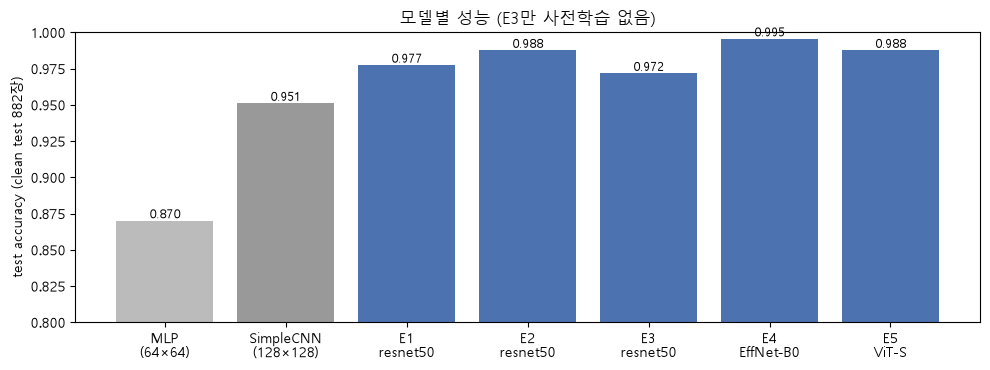

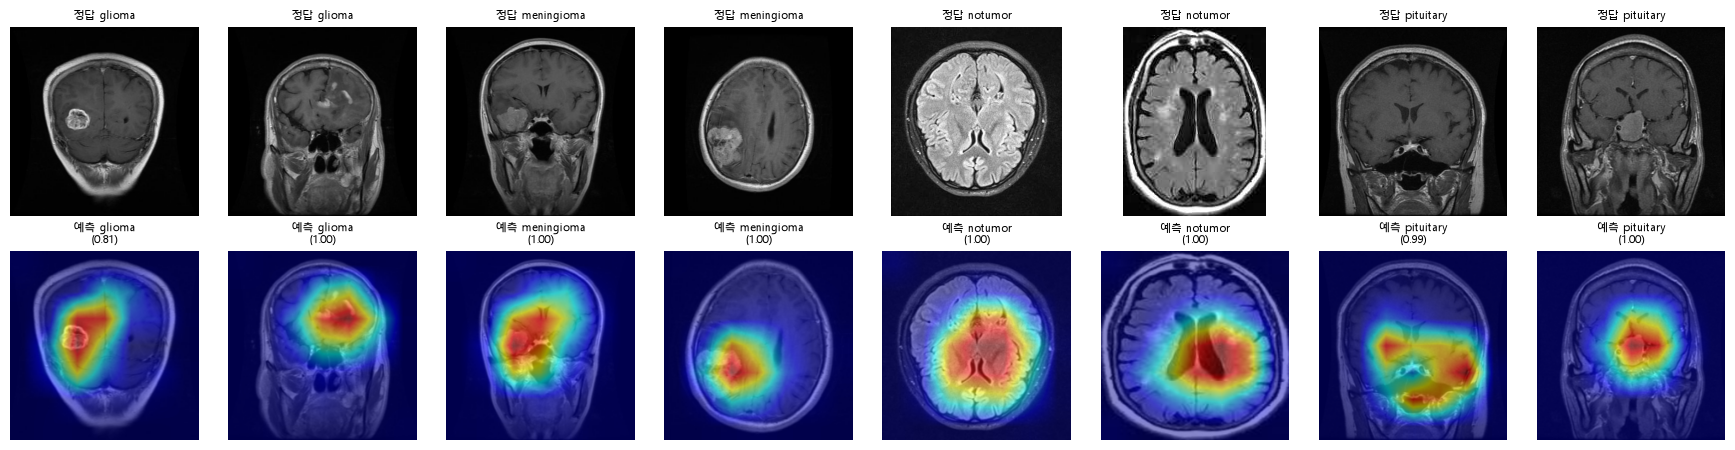

저장: ['gradcam_examples.png', 'model_comparison.png']


In [18]:
# (1) 모델 성능 비교 (노트북 2~4 결과)
res4 = {json.load(open(f, encoding="utf-8"))["tag"]: json.load(open(f, encoding="utf-8")) for f in sorted((OUT / "nb4_results").glob("E*.json"))}
names = ["MLP\n(64×64)", "SimpleCNN\n(128×128)"] + [f"{t}\n{r['model'].split('.')[0].replace('vit_small_patch16_224', 'ViT-S').replace('efficientnet_b0', 'EffNet-B0')}" for t, r in res4.items()]
vals  = [0.870, 0.951] + [r["test_acc"] for r in res4.values()]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.bar(names, vals, color=["#bbb", "#999"] + ["#4C72B0"] * len(res4))
ax.bar_label(bars, fmt="%.3f", fontsize=9); ax.set_ylim(0.8, 1.0); ax.set_ylabel("test accuracy (clean test 882장)")
ax.set_title("모델별 성능 (E3만 사전학습 없음)"); plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=150); plt.show()

# (2) Grad-CAM 예시 (데모 코드 그대로 사용)
ex = sorted(ex_dir.iterdir())
fig, axes = plt.subplots(2, len(ex), figsize=(len(ex) * 2.2, 4.6))
for k, f in enumerate(ex):
    img = np.asarray(Image.open(f).convert("RGB"))
    label, overlay = app.predict(img)
    top = max(label, key=label.get)
    axes[0, k].imshow(img); axes[0, k].set_title(f"정답 {f.stem.rsplit('_', 1)[0]}", fontsize=8)
    axes[1, k].imshow(overlay); axes[1, k].set_title(f"예측 {top.split(' (')[1][:-1]}\n({label[top]:.2f})", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam_examples.png", dpi=150); plt.show()
print("저장:", [p.name for p in FIG_DIR.iterdir()])

### 8-2. README.md 작성

In [19]:
rows = "\n".join(
    f"| {t} | {r['model'].split('.')[0]} | {'✅' if r['pretrained'] else '❌'} | {'✅' if r['crop'] else '❌'} | {'✅' if r['aug'] else '❌'} "
    f"| {r['test_acc']:.3f} | {r['test_macro_f1']:.3f} | {r['glioma→meningioma'] + r['meningioma→glioma']} |"
    for t, r in res4.items())

README = f"""# 프로젝트 1. 뇌종양 MRI 4클래스 분류 — "99%를 얼마나 믿을 수 있나?"

뇌 MRI 단면 한 장을 **glioma / meningioma / notumor / pituitary**로 분류하는 모델을
MLP → 직접 만든 CNN → 사전학습 모델 순으로 만들고, **높은 성능이 정말 "종양을 잘 본다"는 뜻인지** 검증한 프로젝트입니다.

- 🤗 모델: https://huggingface.co/{REPO_ID}
- 🧪 데모: https://huggingface.co/spaces/{SPACE_ID}

## 핵심 결과
![모델 비교](figures/model_comparison.png)

| 실험 | 모델 | 사전학습 | 자르기 | 증강 | test acc | macro F1 | glioma↔meningioma 오분류 |
|---|---|---|---|---|---|---|---|
| 노트북 2 | MLP (64×64) | ❌ | ❌ | ❌ | 0.870 | 0.870 | 76 |
| 노트북 3 | SimpleCNN (128×128) | ❌ | ❌ | ❌ | 0.951 | 0.955 | – |
{rows}

![Grad-CAM 예시](figures/gradcam_examples.png)

## 진행 과정
| 노트북 | 내용 | 주요 발견 |
|---|---|---|
| [01 EDA](notebooks/01_data_explore.ipynb) | 데이터 구조, 채널·크기, **중복·누수 검사** | test의 **31.5%(413장)가 train에 쌍둥이** → 7,023 → 5,980장으로 정리. 클래스별로 촬영 방식(notumor=T2)·단면 방향(pituitary=sagittal·coronal만)이 다름 |
| [02 MLP](notebooks/02_pytorch_mlp.ipynb) | PyTorch 기초, 학습 루프 | acc 0.870, 오류의 66%가 glioma↔meningioma. **외울수록 누수가 점수를 부풀림**(60ep: +1.3%p, meningioma +12.9%p) |
| [03 CNN](notebooks/03_cnn_from_scratch.ipynb) | 합성곱·풀링, 직접 만든 CNN | acc 0.951, glioma↔meningioma 오분류 76 → 27장. lr 3e-4 + cosine으로 학습 안정화. Grad-CAM에서 notumor·pituitary가 **머리 테두리**를 봄 |
| [04 전이학습](notebooks/04_pretrained_transfer.ipynb) | ResNet50, EfficientNet-B0, ViT-Small + 뇌 영역 자르기 + 증강 | 사전학습 모델 0.977~0.995. 사전학습은 성능보다 **학습 안정성**에 큰 효과. Grad-CAM이 뇌 안쪽으로 이동 |
| [05 검증](notebooks/05_evaluation_deep_dive.ipynb) | bootstrap CI, 오답 분석, 지름길 테스트, Grad-CAM 정량화, 보정 | **16×16 로지스틱 회귀로도 80.7%** → 데이터에 지름길 존재. 자르기+증강으로 Grad-CAM 안쪽 비율 0.783 → 0.883 |
| [06 배포](notebooks/06_deploy_huggingface_gradio.ipynb) | 허깅페이스 업로드, Gradio 데모 | 데모 전처리로 test 재평가 → 학습 결과와 일치 확인 |

## 한계 (Limitations)
1. **데이터 지름길**: 종양이 안 보이는 16×16 해상도의 로지스틱 회귀로도 80.7% (notumor 0.92, pituitary 0.88). 높은 정확도 ≠ 종양을 잘 봄
2. **성능 1등 ≠ 올바른 이유**: EfficientNet(0.995)은 notumor에서 테두리를 섞어 보고, 안쪽만 보여줬을 때 가장 잘 맞힌 건 ViT(0.946)
3. **환자 단위 분할 불가** (환자 ID 없음): 오답이 연속 파일 번호에 몰림 → 같은 환자 묶음이 점수를 좌우할 수 있음
4. **외부 검증 없음**, 단일 시드 (EfficientNet > ResNet50·ViT는 통계적으로 단정 불가: Bonferroni 보정 시 비유의)
5. 사진 위 화살표 표시 존재, 단면 한 장 4분류는 실제 진료를 크게 단순화한 문제

## 실행 방법
1. 데이터: [Mendeley Data](https://data.mendeley.com/datasets/5kbjrgsncf/3)에서 받아 `data/raw/`에 압축째로 넣기 (CC BY 4.0)
2. 환경: Python 3.12, PyTorch(CUDA), `pip install timm scikit-learn pandas matplotlib tqdm grad-cam scipy gradio huggingface_hub`
3. `notebooks/` 01 → 06 순서로 실행 (GPU: RTX 3080 기준 전체 약 1.5시간)
4. 데모만 실행: `cd demo && python app.py`

## 데이터 출처
Mendeley Data, *Medical Imaging (CT scan, MRI, X-ray, and Microscopic Imagery) Data* (CC BY 4.0) — Brain Tumor 부분. 원 출처는 Kaggle 공개 데이터셋.
`demo/examples/`의 예시 사진 8장은 이 데이터에서 가져왔습니다.

> ⚠️ 교육·연구 목적의 학습 프로젝트입니다. 의료 진단에 사용할 수 없습니다.
"""
(PROJ / "README.md").write_text(README, encoding="utf-8")
print("작성 완료:", PROJ / "README.md")
print("→ VS Code에서 README.md를 열고 오른쪽 위 '미리보기' 아이콘(Ctrl+Shift+V)으로 확인해보세요.")

작성 완료: D:\yerimlee\medimg-study\01_classification_brain_mri\README.md
→ VS Code에서 README.md를 열고 오른쪽 위 '미리보기' 아이콘(Ctrl+Shift+V)으로 확인해보세요.


## 9. 마무리 체크리스트

- [ ] 3번: 데모 코드로 평가한 결과가 E2(acc 0.988, 오답 11장)와 같은가?
- [ ] 6번: 브라우저에서 데모가 열리고, 예시 사진 예측·Grad-CAM이 나오는가?
- [ ] 5번: 허깅페이스 모델 페이지에서 모델 카드가 잘 보이는가? (확인 후 공개 여부 결정)
- [ ] 8번: README 미리보기에서 그림과 표가 잘 보이는가? 노트북 파일 이름이 링크와 같은가?
- [ ] `HF_USERNAME`이 본인 아이디로 바뀌었는가? (README의 링크에 들어감)
- [ ] **토큰이 노트북 어디에도 적혀 있지 않은가?** (출력 포함)
- [ ] 커밋: `P1-06 배포: 허깅페이스 모델 카드, Gradio 데모, README` → Sync

🎉 **프로젝트 1 완료!** 다음은 프로젝트 2(흉부 X-ray 폐렴 검출, DICOM + YOLO)예요.